# Hot Under El Niño? — Weeks 2–3: *Where is Greater Nairobi hottest, and what would cool it?*

**Author:** Fides Njeri Njuguna
**Area:** Greater Nairobi — Nairobi County plus Kiambu, Thika, Kitengela, Ongata Rongai and Ngong

### Where this fits

Notebook 01 answered **why** it's been hot this season (late rains, clear skies, El Niño, long-term warming). That's the weather, and nobody can switch it off.

This notebook answers the part people *can* act on: **why some neighbourhoods are much hotter than others, and how much green space would help.** It ends with a **solution map** showing where planting trees would cool the most people.

### The steps, in plain words

| Part | Question | What you get at the end |
|---|---|---|
| 1 | Where does heat build up? | **Heat map** at 30 m detail (Landsat) |
| 2 | Where is the greenery, and where is the concrete? | **Green cover map** (Sentinel-2 + ESA WorldCover) |
| 3 | Put both on a 1 km grid | One table where every square kilometre has its heat, trees, buildings, people and altitude |
| 4 | Does greenery actually cool? By how much? | A **"degrees per 10% tree cover"** number, with altitude taken out |
| 5 | How far does a park's cooling reach? | A **cooling-distance curve** ("the effect fades after X m") |
| 6 | Does Greater Nairobi meet the **3-30-300** green standard? | **Gap map** |
| 7 | Where should trees go first? | **Greening priority map** and a top-20 list with coordinates |
| 8 | What would it achieve? | An estimate: "if these areas reached 30% tree cover, about X °C cooler for Y people" |
| 9 | Take it away | Interactive web map, GeoTIFFs for QGIS, a GeoPackage, and every chart as PNG |

### Words you'll see

* **Land surface temperature (LST):** how hot the ground and roofs are, from the satellite's thermal sensor. Not the air temperature, but the best map of *where heat builds up*.
* **Relative heat:** how much hotter a spot is than the Greater Nairobi average *on the same day*. It lets us combine many satellite dates fairly, since some days are hotter overall than others.
* **NDVI:** a 0-to-1 "greenness" score from satellite colours. Healthy leaves reflect a lot of near-infrared light, so dense trees score high and bare soil and roofs score low.
* **The 3-30-300 rule:** a widely used urban-forestry standard. Everyone should **see 3 trees** from home, every neighbourhood should have **30% tree canopy**, and nobody should live more than **300 m** from a green space. We can measure the 30 and the 300 from satellites.

---
## Part 0 — Set up

### Step 0.1: Load the tools

**What:** the same tools as notebook 01, plus `geopandas` (tables with shapes, so we can draw maps).
**Why:** Earth Engine does the heavy satellite work. Then we bring a small summary table back to your laptop for statistics and polished maps.

In [21]:
import time
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.api as sm

OUT = Path("outputs_02")
OUT.mkdir(exist_ok=True)
print("Outputs will be saved in:", OUT.resolve())

Outputs will be saved in: E:\nairobi-heat-elnino\outputs_02


### Step 0.2: Settings

**What:** everything you might want to change, in one place.

**Why each choice:**
* **Hot-dry months (Jan–Mar and Sep–Oct):** heat differences between neighbourhoods show most clearly then, and skies are clear enough for satellites.
* **Several years (2021–2026):** Landsat only passes every 8 days, and clouds hide many passes. Combining six years of hot-season passes gives a reliable picture of *where it's always hottest*, not one lucky day.
* **Greenery from 2024–2026:** we want greenery as it is *now*, since Nairobi changes quickly.
* **Named green spaces:** used only to label the maps (approximate positions).

In [22]:
GEE_PROJECT = "climate-risk-analysis-kenya"  

TOWNS = {
    "Nairobi CBD":   (-1.2864, 36.8172),
    "Kiambu":        (-1.1714, 36.8356),
    "Thika":         (-1.0333, 37.0693),
    "Kitengela":     (-1.4743, 36.9612),
    "Ongata Rongai": (-1.3963, 36.7442),
    "Ngong":         (-1.3550, 36.6650),
}
TOWN_BUFFER_M = 4000

GREEN_LABELS = {          # approximate positions, for map labels only
    "Karura Forest":      (-1.2400, 36.8330),
    "Ngong Road Forest":  (-1.3020, 36.7430),
    "Nairobi Nat. Park":  (-1.3700, 36.8500),
    "City Park":          (-1.2600, 36.8240),
    "Arboretum":          (-1.2740, 36.8050),
}

LANDSAT_YEARS = (2021, 2026)
GREEN_YEARS = (2024, 2026)
HOT_MONTHS = [(1, 3), (9, 10)]       # Jan–Mar and Sep–Oct
GRID_M = 1000                        # 1 km squares
UTM = "EPSG:32737"                   # UTM zone 37 South: Nairobi's metre-based map projection
CANOPY_TARGET = 0.30                 # the "30" in 3-30-300
ACCESS_M = 300                       # the "300" in 3-30-300
MIN_PEOPLE_KM2 = 500                 # a square counts as "where people live" above this density

### Step 0.3: Connect to Earth Engine and draw the study area

**What:** log in, then build the same study area as notebook 01: Nairobi County plus a 4 km circle around each surrounding town.
**Why the same area?** So both notebooks tell one story about one place.

In [23]:
import ee
import geemap

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)

nairobi_county = (ee.FeatureCollection("FAO/GAUL/2015/level1")
                  .filter(ee.Filter.eq("ADM0_NAME", "Kenya"))
                  .filter(ee.Filter.eq("ADM1_NAME", "Nairobi")))
town_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([lon, lat]).buffer(TOWN_BUFFER_M), {"name": n})
    for n, (lat, lon) in TOWNS.items()])
metro_geom = nairobi_county.geometry().union(town_fc.geometry(), maxError=100)

# A copy of the outline on your laptop, for drawing maps later
metro_gdf = gpd.GeoDataFrame.from_features(
    [{"type": "Feature", "geometry": metro_geom.getInfo(), "properties": {}}], crs="EPSG:4326")
print(f"Study area: about {metro_geom.area(maxError=100).divide(1e6).getInfo():,.0f} km²")

Study area: about 935 km²


---
## Part 1 — Where does heat build up? (Landsat, 30 m)

### Step 1.1: Build a typical hot-season heat map from every usable Landsat pass

**What:**
1. Take all Landsat 8 and 9 images over the area in the hot-dry months, 2021–2026, keeping scenes that are less than 40% cloudy overall.
2. In each image, **hide cloudy pixels**. Each pixel has a quality flag saying "cloud", "cloud shadow" or "cirrus", and we drop those.
3. Convert the thermal band to °C. Landsat stores it as whole numbers; the official recipe is × 0.00341802 + 149, which gives Kelvin, then − 273.15.
4. For every 30 m pixel, take the **median** of all its clear readings: its *typical* hot-season surface temperature.
5. Work out **relative heat**: each pixel minus the middle value of the whole study area.

**Why the median of many passes?** One pass can be unusually hot or cool, and clouds hide parts of it. The median across dozens of passes gives each spot's *typical* hot-season temperature, so one odd day can't distort the map.

**Why relative heat?** It turns the map into *"how much hotter or cooler than Greater Nairobi's middle value"*. That's what matters for comparing neighbourhoods, and it reads the same whatever the overall weather was.

**Why this design?** Earlier versions calculated statistics image by image. That runs dozens of calculations at once and hits Earth Engine's free limit ("Too many concurrent aggregations"). This version needs just one.

In [24]:
def months_filter(ranges):
    return ee.Filter.Or(*[ee.Filter.calendarRange(a, b, "month") for a, b in ranges])

def landsat_lst(img):
    qa = img.select("QA_PIXEL")
    clear = (qa.bitwiseAnd(1 << 1).eq(0)        # dilated cloud
             .And(qa.bitwiseAnd(1 << 2).eq(0))   # cirrus
             .And(qa.bitwiseAnd(1 << 3).eq(0))   # cloud
             .And(qa.bitwiseAnd(1 << 4).eq(0)))  # cloud shadow
    return (img.select("ST_B10").multiply(0.00341802).add(149.0).subtract(273.15)
            .updateMask(clear).rename("lst"))

landsat = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
           .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
           .filterBounds(metro_geom)
           .filterDate(f"{LANDSAT_YEARS[0]}-01-01", f"{LANDSAT_YEARS[1] + 1}-01-01")
           .filter(months_filter(HOT_MONTHS))
           .filter(ee.Filter.lt("CLOUD_COVER", 40))
           .map(landsat_lst))

n_scenes = landsat.size().getInfo()
print(f"Landsat passes used: {n_scenes}")
assert n_scenes >= 10, "Too few passes — widen LANDSAT_YEARS or HOT_MONTHS in Step 0.2."

lst_abs = landsat.median().clip(metro_geom)                       # typical hot-season surface °C
area_median = ee.Number(lst_abs.reduceRegion(ee.Reducer.median(), metro_geom, 90,
                                             maxPixels=1e10, bestEffort=True).get("lst"))
lst_rel = lst_abs.subtract(area_median).rename("lst_rel")         # °C hotter/cooler than the area's middle value
print(f"Greater Nairobi's middle hot-season surface temperature: {area_median.getInfo():.1f} °C")


Landsat passes used: 64
Greater Nairobi's middle hot-season surface temperature: 38.1 °C


### Step 2.1: Map the greenery and the concrete

**What:** three layers:
1. **NDVI (greenness)** from Sentinel-2 (10 m detail), 2024–2026 hot-season passes. Clouds are removed with Google's *Cloud Score+* layer, which scores how clear each pixel is.
2. **Tree cover** and **built-up** areas from **ESA WorldCover**, a global land cover map at 10 m that labels each pixel as trees, grass, crops, built-up and so on.
3. **Altitude** (SRTM) and **people** (WorldPop, people per 100 m square).

**Why both NDVI and WorldCover?** NDVI is up to date but mixes trees, lawns and crops. WorldCover says *trees* specifically, which is what the 30% canopy rule needs, but it's from 2021. Together they're stronger than either alone.

**Why altitude?** Higher ground is naturally cooler: Ngong is about 500 m higher than Thika. Without accounting for altitude, we might credit trees for cooling that the hills are doing.

**Why people?** A hot square with nobody living in it is a lower priority than a hot square with 20,000 residents.

In [25]:
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
      .filterBounds(metro_geom)
      .filterDate(f"{GREEN_YEARS[0]}-01-01", f"{GREEN_YEARS[1] + 1}-01-01")
      .filter(months_filter(HOT_MONTHS))
      .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60))
      .linkCollection(ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED"), ["cs_cdf"]))
print("Sentinel-2 passes used:", s2.size().getInfo())
ndvi = (s2.map(lambda img: img.normalizedDifference(["B8", "B4"]).rename("ndvi")
                         .updateMask(img.select("cs_cdf").gte(0.6)))
          .median().clip(metro_geom))

worldcover = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
trees = worldcover.eq(10).rename("tree")
built = worldcover.eq(50).rename("built")
elev = ee.Image("USGS/SRTMGL1_003").rename("elev")
pop = (ee.ImageCollection("WorldPop/GP/100m/pop")
       .filter(ee.Filter.eq("country", "KEN")).filter(ee.Filter.eq("year", 2020))
       .first().rename("pop"))           # people per 100 m × 100 m square

Sentinel-2 passes used: 162


### Step 2.2: How far is every spot from a real patch of trees?

**What:**
1. Find **tree patches of at least 1 hectare** (about one and a half football pitches). We count connected tree pixels and ignore single street trees.
2. For every 30 m pixel, measure the **distance to the nearest such patch**.

**Why 1 hectare?** A patch needs some size to create its own cooler air and be usable as a green space. The 300 m part of 3-30-300 is about reaching a real green space, not one tree.

In [26]:
utm10, utm30 = ee.Projection(UTM).atScale(10), ee.Projection(UTM).atScale(30)
patch = (trees.selfMask().reproject(utm10)
         .connectedPixelCount(128, True).gte(100)       # ≥100 pixels of 10 m = 1 hectare
         .unmask(0))
patch30 = patch.reduceResolution(ee.Reducer.max(), maxPixels=16).reproject(utm30)
dist_green = (patch30.fastDistanceTransform(512).sqrt().multiply(30)
              .reproject(utm30).rename("dist_green").clip(metro_geom))   # metres

### Step 2.3: Look before you calculate: the interactive map

**What:** put every layer on one zoomable map: heat, greenness, trees, distance to green. Then save it as a web page you can open in any browser and share.

**Why look first?** It's the fastest error check there is. Hot spots should sit on industrial areas, dense estates and bare ground; cool spots on Karura, Ngong Road Forest and the Arboretum. If the map looks wrong, stop and investigate before trusting any number.

In [27]:
heat_vis = {"min": -6, "max": 6, "palette": ["#2166ac", "#67a9cf", "#f7f7f7", "#ef8a62", "#b2182b"]}
m = geemap.Map(center=[-1.28, 36.85], zoom=11)
m.add_basemap("SATELLITE")
m.addLayer(ndvi, {"min": 0, "max": 0.8, "palette": ["#f7fcf5", "#74c476", "#00441b"]}, "Greenness (NDVI)", False)
m.addLayer(trees.selfMask(), {"palette": ["#1b7837"]}, "Tree cover (WorldCover)", False)
m.addLayer(dist_green.updateMask(dist_green.gt(0)), {"min": 0, "max": 1000, "palette": ["#fee8c8", "#e34a33"]},
           "Distance to 1 ha+ tree patch (m)", False)
m.addLayer(lst_rel, heat_vis, "Relative heat (°C vs area median)")
m.add_colorbar(heat_vis, label="°C hotter (red) / cooler (blue) than the area's middle value")
m

Map(center=[-1.28, 36.85], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
## Part 3 — Put everything on a 1 km grid

**What:** cover the study area with **1 km × 1 km squares** and, for each square, compute:

| Column | Meaning |
|---|---|
| `lst_rel` | average relative heat (°C) |
| `lst_abs` | average hot-season surface temperature (°C) |
| `ndvi` | average greenness |
| `tree`, `built` | share of the square that is trees / buildings and roads (0–1) |
| `elev` | average altitude (m) |
| `pop` | people per 100 m square (we convert it to people per km²) |
| `access300` | share of the square within 300 m of a 1 ha+ tree patch |

**Why squares instead of wards?** Squares are all the same size, so comparisons are fair (wards vary hugely). They also cover Kiambu, Thika and Kajiado the same way as Nairobi. You can later join the results to ward boundaries in QGIS.

**Saved for the day:** the grid is saved to `outputs_02/grid_raw.gpkg`, so re-running the notebook later the same day reuses it instead of recalculating.

**If Earth Engine says "Computation timed out":** that's a size limit for live requests. Change `GRID_M` to 2000 to test, or use the export alternative in the comment at the bottom of the cell.

In [28]:
cache = OUT / "grid_raw.gpkg"
if cache.exists() and dt.date.fromtimestamp(cache.stat().st_mtime) == dt.date.today():
    grid_gdf = gpd.read_file(cache)
    print("Using the grid saved earlier today.")
else:
    grid = metro_geom.coveringGrid(ee.Projection(UTM).atScale(GRID_M))
    stack = ee.Image.cat([
        lst_rel.rename("lst_rel"), lst_abs.rename("lst_abs"), ndvi, trees, built, elev, pop,
        dist_green.lte(ACCESS_M).rename("access300"),
    ])
    grid_stats = (stack.reduceRegions(collection=grid, reducer=ee.Reducer.mean(), scale=30, crs=UTM, tileScale=4)
                  .map(lambda f: f.transform("EPSG:4326", 1)))      # return corners in degrees, not metres
    grid_gdf = gpd.GeoDataFrame.from_features(grid_stats.getInfo()["features"], crs="EPSG:4326")

# Safety check: if the corners still came back in metres (UTM), relabel them and convert to degrees
if abs(grid_gdf.total_bounds).max() > 180:
    grid_gdf = grid_gdf.set_crs(UTM, allow_override=True).to_crs("EPSG:4326")
grid_gdf.to_file(cache, driver="GPKG")
print(f"{len(grid_gdf):,} squares; bounds (should be about 36.6, -1.5, 37.1, -1.0):", grid_gdf.total_bounds.round(2))

# Export alternative if the download times out:
# task = ee.batch.Export.table.toDrive(grid_stats, "greater_nairobi_grid", fileFormat="GeoJSON"); task.start()
# ...then download the GeoJSON from Google Drive and read it with gpd.read_file(...)


Using the grid saved earlier today.
1,093 squares; bounds (should be about 36.6, -1.5, 37.1, -1.0): [36.63 -1.52 37.11 -0.99]


### Step 3.2: Tidy the table

**What:** drop squares with no data, convert units (share → %, people per 100 m square → people per km²), label each square with its nearest town, and mark where people actually live.

**Why label towns?** So results can be told town by town: *"In Kitengela, X% of squares are below 30% tree cover."*

In [29]:
g = grid_gdf.dropna(subset=["lst_rel", "tree", "built", "elev"]).copy()
g["tree_pct"] = g["tree"] * 100
g["built_pct"] = g["built"] * 100
g["people_km2"] = g["pop"].fillna(0) * 100
g["access300_pct"] = g["access300"].fillna(0) * 100
g["populated"] = g["people_km2"] >= MIN_PEOPLE_KM2

cent = g.to_crs(UTM).geometry.centroid.to_crs("EPSG:4326")
g["lat"], g["lon"] = cent.y.round(4), cent.x.round(4)

def nearest_town(lat, lon):
    best, best_d = "Nairobi (rest of county)", 1e9
    for n, (tl, tn) in TOWNS.items():
        d = np.hypot((lat - tl) * 111, (lon - tn) * 111)     # km, fine at the equator
        if d < best_d:
            best, best_d = n, d
    return best if best_d <= 5 else "Nairobi (rest of county)"

g["area"] = [nearest_town(a, b) for a, b in zip(g.lat, g.lon)]
print(f"Squares with data: {len(g):,}; where people live (≥{MIN_PEOPLE_KM2}/km²): {g.populated.sum():,}")
g[["area", "lst_rel", "tree_pct", "built_pct", "people_km2"]].describe().round(1)

Squares with data: 1,093; where people live (≥500/km²): 691


,lst_rel,tree_pct,built_pct,people_km2
count,1093.0,1093.0,1093.0,1093.0
mean,-0.6,21.0,28.1,4396.0
std,3.7,25.6,28.8,9628.9
min,-12.0,0.0,0.0,6.8
25%,-3.1,1.0,3.0,261.4
50%,-0.1,7.9,18.5,934.5
75%,2.1,36.3,45.3,3807.8
max,7.2,99.8,98.2,102540.9


### Step 3.3: The heat map and the green map

**What:** draw the two headline maps from the grid:
* **Map 1, relative heat:** each square's colour shows how much hotter (darker red) or cooler (pale) it runs than Greater Nairobi's middle value.
* **Map 2, tree cover:** each square's share of trees.

**How to read them together:** put them side by side. If the dark-red squares are the pale squares on the tree map, and vice versa, you're *seeing* the cooling effect before measuring it.

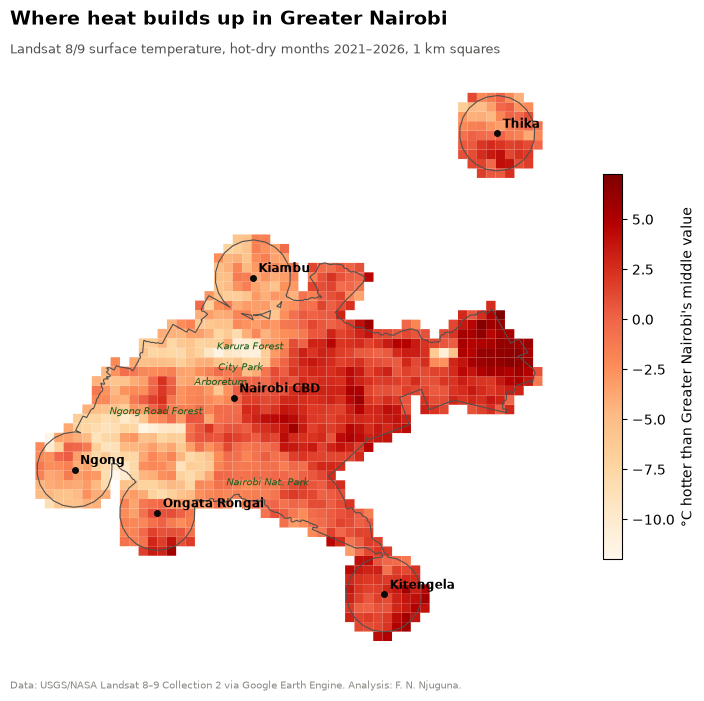

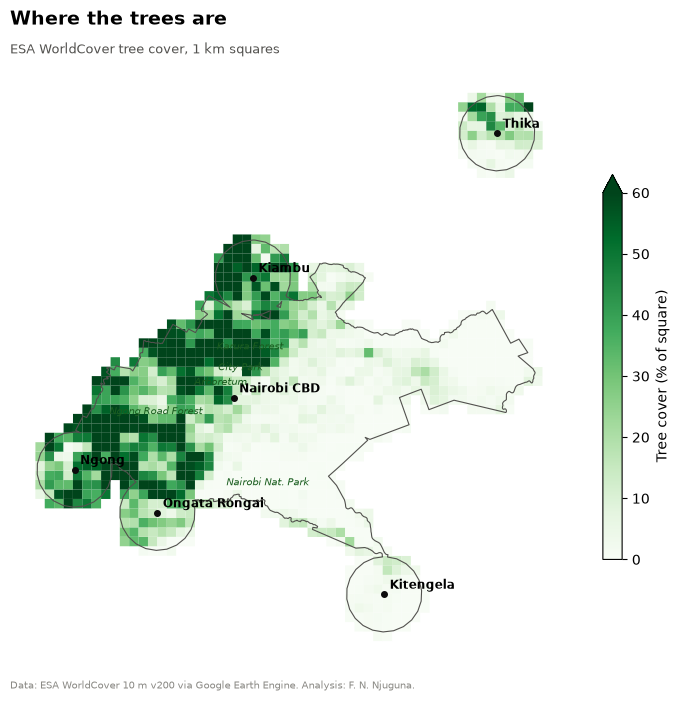

In [30]:
def base_map(ax, title, subtitle):
    metro_gdf.boundary.plot(ax=ax, color="#52514e", linewidth=0.8)
    for n, (lat, lon) in TOWNS.items():
        ax.plot(lon, lat, "o", ms=4, color="#0b0b0b")
        ax.annotate(n, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=8.5, fontweight="bold")
    for n, (lat, lon) in GREEN_LABELS.items():
        ax.annotate(n, (lon, lat), fontsize=7.5, color="#1b5e20", style="italic", ha="center")
    ax.set_axis_off()
    # Title and subtitle sit just above the map (not at the top of the page)
    ax.text(0, 1.06, title, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom")
    ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color="#52514e", va="bottom", wrap=True)


def credit(fig, text):
    ax = fig.axes[0]
    ax.text(0, -0.02, text, transform=ax.transAxes, fontsize=7.5, color="#8a8984", va="top")

fig, ax = plt.subplots(figsize=(9, 10))
g.plot(column="lst_rel", cmap="OrRd", ax=ax, legend=True, linewidth=0,
       legend_kwds={"label": "°C hotter than Greater Nairobi's middle value", "shrink": 0.5})
base_map(ax, "Where heat builds up in Greater Nairobi",
         f"Landsat 8/9 surface temperature, hot-dry months {LANDSAT_YEARS[0]}–{LANDSAT_YEARS[1]}, 1 km squares")
credit(fig, "Data: USGS/NASA Landsat 8–9 Collection 2 via Google Earth Engine. Analysis: F. N. Njuguna.")
fig.savefig(OUT / "map1_heat.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 10))
g.plot(column="tree_pct", cmap="Greens", ax=ax, legend=True, linewidth=0, vmin=0, vmax=60,
       legend_kwds={"label": "Tree cover (% of square)", "shrink": 0.5})
base_map(ax, "Where the trees are", "ESA WorldCover tree cover, 1 km squares")
credit(fig, "Data: ESA WorldCover 10 m v200 via Google Earth Engine. Analysis: F. N. Njuguna.")
fig.savefig(OUT / "map2_tree_cover.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 4 — Does greenery cool? By how much?

### Step 4.1: Measure it, with altitude and buildings taken into account

**What:** a *multiple regression* across all the squares:

> heat ≈ (effect of tree cover) + (effect of built-up area) + (effect of altitude)

It finds each effect **while holding the others steady**. So the tree number means: *two squares at the same altitude with the same amount of buildings, one with 10% more trees, differ by this many degrees.*

**Why this matters:** this single number, **"°C per 10% more tree cover"**, is your evidence that greening works *here*, measured on Greater Nairobi's own data, not borrowed from a study in Europe.

In [31]:
def verdict(p):
    return "a clear link" if p < 0.05 else ("a weak hint" if p < 0.10 else "no clear link")

X = pd.DataFrame({"tree_pct_per10": g.tree_pct / 10, "built_pct_per10": g.built_pct / 10,
                  "elev_per100m": g.elev / 100})
cool_model = sm.OLS(g.lst_rel, sm.add_constant(X)).fit()
c, p = cool_model.params, cool_model.pvalues
b_tree10 = c["tree_pct_per10"]
print(f"Each extra 10% tree cover:    {b_tree10:+.2f} °C  ({verdict(p['tree_pct_per10'])}, p = {p['tree_pct_per10']:.3f})")
print(f"Each extra 10% built-up area: {c['built_pct_per10']:+.2f} °C  ({verdict(p['built_pct_per10'])})")
print(f"Each extra 100 m of altitude: {c['elev_per100m']:+.2f} °C  ({verdict(p['elev_per100m'])})")
print(f"Together these explain {cool_model.rsquared:.0%} of the heat differences between squares.")

Each extra 10% tree cover:    -1.02 °C  (a clear link, p = 0.000)
Each extra 10% built-up area: +0.14 °C  (a clear link)
Each extra 100 m of altitude: -0.58 °C  (a clear link)
Together these explain 78% of the heat differences between squares.


### Step 4.2: Picture it

**What:** a scatter of every square: tree cover across, heat up. The line shows the average heat for squares in each 5% tree-cover band.
**How to read it:** a line sloping **down to the right** means more trees, less heat. Where the line flattens out shows the point where adding more trees stops making much difference.

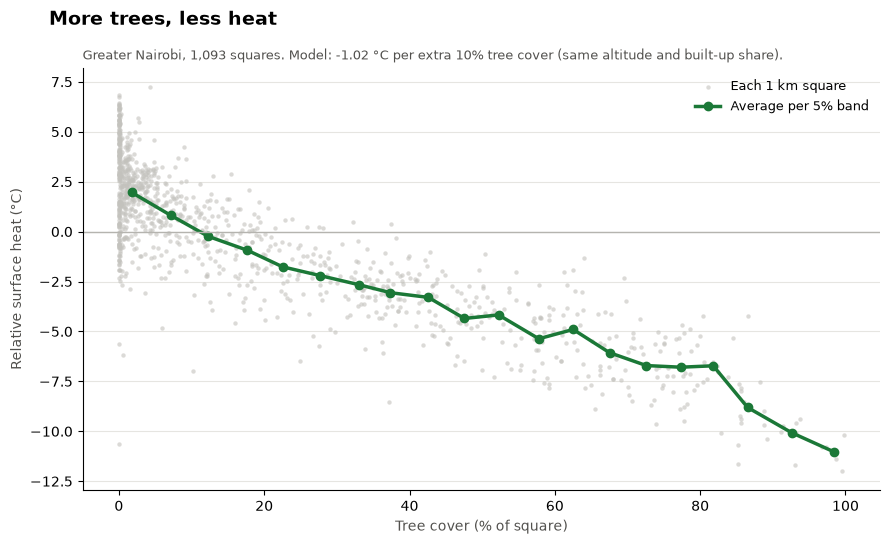

In [32]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(g.tree_pct, g.lst_rel, s=10, color="#c3c2bd", alpha=0.6, linewidth=0, label="Each 1 km square")
bins = pd.cut(g.tree_pct, np.arange(0, 105, 5))
line = g.groupby(bins, observed=True).agg(x=("tree_pct", "mean"), y=("lst_rel", "mean"), n=("lst_rel", "size"))
line = line[line.n >= 5]
ax.plot(line.x, line.y, color="#1b7837", lw=2.5, marker="o", ms=6, label="Average per 5% band")
ax.axhline(0, color="#b5b4af", lw=1)
ax.grid(axis="y", color="#e6e5e1"); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlabel("Tree cover (% of square)", color="#52514e")
ax.set_ylabel("Relative surface heat (°C)", color="#52514e")
fig.suptitle("More trees, less heat", x=0.06, ha="left", fontsize=14, fontweight="bold")
ax.set_title(f"Greater Nairobi, {len(g):,} squares. Model: {b_tree10:+.2f} °C per extra 10% tree cover "
             "(same altitude and built-up share).", loc="left", fontsize=9, color="#52514e")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "chart1_trees_vs_heat.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 5 — How far does a green space's cooling reach?

**What:** take **only built-up pixels** (homes, roads, rooftops) and group them by distance from the nearest 1 ha+ tree patch: 0–60 m, 60–120 m, and so on out to 1.5 km. Then average the heat in each group.

**Why only built-up pixels?** We want to know whether *living next to* a green space keeps *your street* cooler, not whether the trees themselves are cool (we know they are).

**How to read the curve:** heat rises as you move away from green space, then levels off. **Where it levels off is how far the cooling reaches.** The rise from the first point to the plateau is how much cooling a nearby green space gives. Planners can use that distance: *"every home should be within X m of a tree patch."*

In [33]:
STEP = 60
bin_img = dist_green.divide(STEP).floor().min(25).int().rename("bin")      # 25 × 60 m = 1.5 km+
built30 = built.reduceResolution(ee.Reducer.mean(), maxPixels=16).reproject(utm30).gte(0.5)
sample = lst_rel.rename("lst").addBands(bin_img).updateMask(built30.And(dist_green.gt(0)))
res = sample.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True).group(groupField=1, groupName="bin"),
    geometry=metro_geom, scale=30, crs=UTM, maxPixels=1e10, tileScale=4)
cool_df = pd.DataFrame(res.get("groups").getInfo())
inside_green = lst_rel.updateMask(patch30).reduceRegion(ee.Reducer.mean(), metro_geom, 30, crs=UTM,
                                                        maxPixels=1e10, tileScale=4).get("lst_rel").getInfo()
cool_df.to_csv(OUT / "table_cooling_distance.csv", index=False)

Inside 1 ha+ tree patches: -5.5 °C (relative)
Built-up areas right next to green space: -1.6 °C; 1 km+ away: +2.4 °C
→ Living next to a green space is about 4.0 °C cooler; the effect fades by about 450 m.


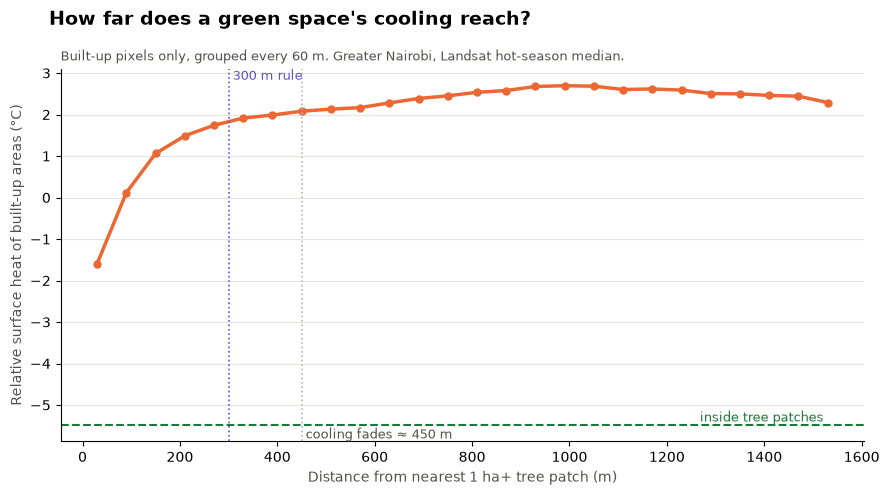

In [34]:
cool_df = cool_df.sort_values("bin")
cool_df = cool_df[cool_df["count"] >= 200]                 # skip thin groups
cool_df["dist_m"] = (cool_df["bin"] + 0.5) * STEP
near, far = cool_df["mean"].iloc[0], cool_df["mean"].iloc[-5:].mean()
# where the curve reaches 90% of its rise = "how far the cooling reaches"
reach = cool_df.loc[cool_df["mean"] >= near + 0.9 * (far - near), "dist_m"].min()
print(f"Inside 1 ha+ tree patches: {inside_green:+.1f} °C (relative)")
print(f"Built-up areas right next to green space: {near:+.1f} °C; 1 km+ away: {far:+.1f} °C")
print(f"→ Living next to a green space is about {far - near:.1f} °C cooler; the effect fades by about {reach:.0f} m.")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cool_df.dist_m, cool_df["mean"], color="#eb6834", lw=2.5, marker="o", ms=5)
ax.axhline(inside_green, color="#1b7837", ls="--", lw=1.5)
ax.text(cool_df.dist_m.max(), inside_green, "inside tree patches ", color="#1b7837", ha="right", va="bottom", fontsize=9)
ax.axvline(reach, color="#b5b4af", ls=":", lw=1.2)
ax.text(reach, ax.get_ylim()[0], f" cooling fades ≈ {reach:.0f} m", fontsize=9, color="#52514e", va="bottom")
ax.axvline(ACCESS_M, color="#6250d6", ls=":", lw=1.2)
ax.text(ACCESS_M, ax.get_ylim()[1], f" {ACCESS_M} m rule", fontsize=9, color="#6250d6", va="top")
ax.grid(axis="y", color="#e6e5e1"); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlabel("Distance from nearest 1 ha+ tree patch (m)", color="#52514e")
ax.set_ylabel("Relative surface heat of built-up areas (°C)", color="#52514e")
fig.suptitle("How far does a green space's cooling reach?", x=0.06, ha="left", fontsize=14, fontweight="bold")
ax.set_title(f"Built-up pixels only, grouped every {STEP} m. Greater Nairobi, Landsat hot-season median.",
             loc="left", fontsize=9, color="#52514e")
fig.tight_layout(); fig.savefig(OUT / "chart2_cooling_distance.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 6 — Does Greater Nairobi meet the 3-30-300 rule?

**What:** for every square where people live, check:
* **30:** is tree cover at least 30%?
* **300:** is at least half the square within 300 m of a 1 ha+ tree patch?

Each square then falls into one of four groups: meets both, fails canopy only, fails access only, fails both.

**Why use an existing standard?** It turns "we need more trees" into a **measurable target** that city planners, UN-Habitat and funders already recognise. Your map shows *exactly where* the target is missed.

(The "3 trees visible from home" part needs street-level photos, so it's beyond satellite data. Say so in your brief.)

                  squares        people  people_share
rule_class                                           
Below 30% canopy      219  1.982866e+06         0.419
Fails both            242  2.108034e+06         0.446
Meets both            230  6.390615e+05         0.135


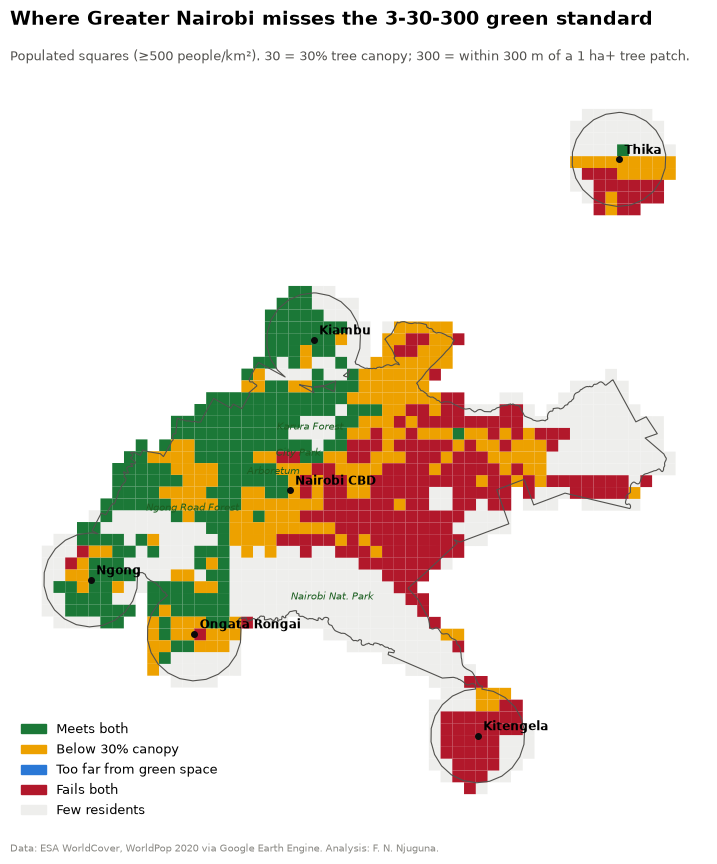

In [35]:
pp = g[g.populated].copy()
pp["meets30"] = pp.tree >= CANOPY_TARGET
pp["meets300"] = pp.access300 >= 0.5
pp["rule_class"] = np.select(
    [pp.meets30 & pp.meets300, ~pp.meets30 & pp.meets300, pp.meets30 & ~pp.meets300],
    ["Meets both", "Below 30% canopy", "Too far from green space"], "Fails both")
summary_rule = pp.groupby("rule_class").agg(squares=("rule_class", "size"), people=("people_km2", "sum"))
summary_rule["people_share"] = (summary_rule.people / summary_rule.people.sum()).round(3)
print(summary_rule)

cats = {"Meets both": "#1b7837", "Below 30% canopy": "#eda100",
        "Too far from green space": "#2a78d6", "Fails both": "#b2182b"}
fig, ax = plt.subplots(figsize=(9, 10))
g[~g.populated].plot(ax=ax, color="#eeeeec", linewidth=0)
for k, col in cats.items():
    sub = pp[pp.rule_class == k]
    if len(sub):
        sub.plot(ax=ax, color=col, linewidth=0)
base_map(ax, "Where Greater Nairobi misses the 3-30-300 green standard",
         f"Populated squares (≥{MIN_PEOPLE_KM2} people/km²). 30 = 30% tree canopy; 300 = within 300 m of a 1 ha+ tree patch.")
ax.legend(handles=[Patch(color=v, label=k) for k, v in cats.items()] + [Patch(color="#eeeeec", label="Few residents")],
          loc="lower left", frameon=False, fontsize=9)
credit(fig, "Data: ESA WorldCover, WorldPop 2020 via Google Earth Engine. Analysis: F. N. Njuguna.")
fig.savefig(OUT / "map3_3-30-300_gaps.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 7 — The solution map: where should trees go first?

**What:** for every square where people live, score three things from 0 to 1. Each score is the square's *percentile*: 1 means "highest of all squares".
1. **Heat:** how hot it runs.
2. **Green gap:** how little tree cover it has.
3. **People:** how many residents would benefit.

The **priority score** is the average of the three. The top 10% of squares are **"Act first"**, the next 20% **"Act next"**.

**Why these three, equally weighted?** Trees help most where it's hot, where there are no trees yet, and where many people live. Equal weights are the simplest choice to defend. If someone asks *"why not weight people double?"*, change one line and show the map barely moves (or does, which is also worth knowing).

**What you get:** the priority map, plus a **top-20 list with coordinates and a Google Maps link** for each square. That's the most tangible output in the project: someone could drive to these places tomorrow.

,rank,area,lat,lon,lst_rel,tree_pct,built_pct,people_km2,priority
688,1,Nairobi (rest of county),-1.26,36.93,4.32,0.09,96.55,24750.34,0.96
593,2,Nairobi (rest of county),-1.28,36.91,3.10,0.09,96.85,27557.27,0.94
687,3,Nairobi (rest of county),-1.26,36.92,2.98,0.75,96.70,50280.24,0.93
433,4,Nairobi (rest of county),-1.32,36.88,3.43,1.08,88.72,33434.66,0.92
639,5,Nairobi (rest of county),-1.27,36.91,2.71,0.45,96.13,31971.53,0.91
594,6,Nairobi (rest of county),-1.28,36.92,3.04,0.78,48.56,23785.95,0.91
894,7,Nairobi (rest of county),-1.22,36.94,4.03,0.09,84.80,8629.96,0.91
468,8,Nairobi (rest of county),-1.31,36.87,4.34,1.08,96.88,14715.70,0.90
592,9,Nairobi (rest of county),-1.28,36.90,3.06,1.08,96.46,25159.81,0.90
432,10,Nairobi (rest of county),-1.32,36.87,5.69,2.58,95.56,27140.45,0.90


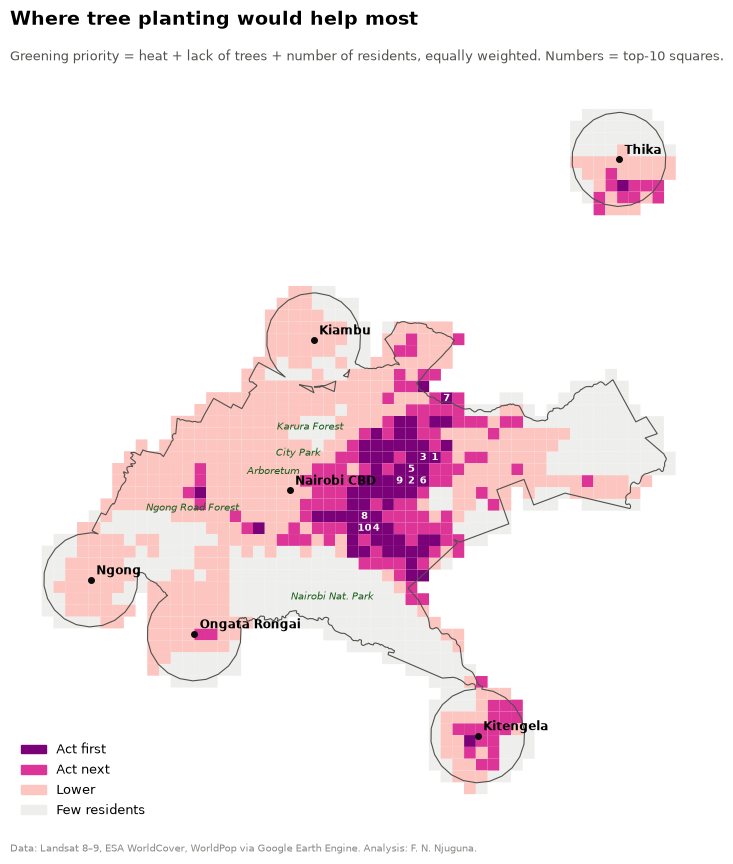

In [36]:
W_HEAT, W_GAP, W_PEOPLE = 1, 1, 1       # change to test other weightings

pp["s_heat"] = pp.lst_rel.rank(pct=True)
pp["s_gap"] = (-pp.tree).rank(pct=True)
pp["s_people"] = pp.people_km2.rank(pct=True)
pp["priority"] = (W_HEAT * pp.s_heat + W_GAP * pp.s_gap + W_PEOPLE * pp.s_people) / (W_HEAT + W_GAP + W_PEOPLE)
q90, q70 = pp.priority.quantile(0.90), pp.priority.quantile(0.70)
pp["priority_class"] = np.select([pp.priority >= q90, pp.priority >= q70], ["Act first", "Act next"], "Lower")

top = (pp.sort_values("priority", ascending=False).head(20)
       [["area", "lat", "lon", "lst_rel", "tree_pct", "built_pct", "people_km2", "priority"]].round(2))
top["google_maps"] = [f"https://www.google.com/maps?q={a},{b}" for a, b in zip(top.lat, top.lon)]
top.insert(0, "rank", range(1, len(top) + 1))
top.to_csv(OUT / "table_top20_greening_priority.csv", index=False)
display(top.drop(columns="google_maps"))

pcols = {"Act first": "#7a0177", "Act next": "#dd3497", "Lower": "#fcc5c0"}
fig, ax = plt.subplots(figsize=(9, 10))
g[~g.populated].plot(ax=ax, color="#eeeeec", linewidth=0)
for k, col in pcols.items():
    pp[pp.priority_class == k].plot(ax=ax, color=col, linewidth=0)
top_pts = pp.sort_values("priority", ascending=False).head(10)
for i, (lat, lon) in enumerate(zip(top_pts.lat, top_pts.lon), 1):
    ax.annotate(str(i), (lon, lat), fontsize=7, color="white", fontweight="bold", ha="center", va="center")
base_map(ax, "Where tree planting would help most",
         "Greening priority = heat + lack of trees + number of residents, equally weighted. Numbers = top-10 squares.")
ax.legend(handles=[Patch(color=v, label=k) for k, v in pcols.items()] + [Patch(color="#eeeeec", label="Few residents")],
          loc="lower left", frameon=False, fontsize=9)
credit(fig, "Data: Landsat 8–9, ESA WorldCover, WorldPop via Google Earth Engine. Analysis: F. N. Njuguna.")
fig.savefig(OUT / "map4_greening_priority.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 8 — What would it achieve?

**What:** use the "°C per 10% tree cover" number from Step 4.1 to estimate how much cooler each **"Act first"** and **"Act next"** square would be if its tree cover rose to **30%**, and how many people live there.

**Why:** a solution needs a *size*. "Plant trees" is a wish. *"Bringing the 10% hottest, least green neighbourhoods up to 30% canopy could cool surfaces by about X °C for roughly Y people"* is a proposal.

**Be honest about it in the brief:** it's an estimate from a statistical relationship, not a guarantee. Real cooling depends on species, watering and where exactly trees go. It shows the *scale* of the benefit.

In [37]:
target = pp[pp.priority_class.isin(["Act first", "Act next"]) & (pp.tree < CANOPY_TARGET)].copy()
target["extra_tree_pct"] = (CANOPY_TARGET - target.tree) * 100
target["cooling_C"] = b_tree10 * target.extra_tree_pct / 10          # negative = cooler
people = target.people_km2.sum() * (GRID_M / 1000) ** 2
avg_cool = np.average(target.cooling_C, weights=target.people_km2)
print(f"Squares: {len(target)}; residents: about {round(people, -3):,.0f}")
print(f"Tree cover would rise by {target.extra_tree_pct.mean():.0f} percentage points on average.")
print(f"Estimated surface cooling, weighted by residents: {avg_cool:+.1f} °C")
target.groupby("area").agg(squares=("priority", "size"), people=("people_km2", "sum"),
                            avg_cooling_C=("cooling_C", "mean")).round(1).sort_values("people", ascending=False)

Squares: 208; residents: about 3,029,000
Tree cover would rise by 27 percentage points on average.
Estimated surface cooling, weighted by residents: -2.6 °C


,squares,people,avg_cooling_C
area,,,
Nairobi (rest of county),150,2363277.3,-2.7
Nairobi CBD,26,522979.0,-2.5
Kitengela,19,67049.0,-2.9
Thika,11,44121.9,-2.9
Ongata Rongai,2,31981.9,-2.4


### Step 8.2: Town-by-town summary

**What:** for each town area, the average heat, tree cover, and share of residents in "Act first" squares.
**Why:** each town gets one line it can quote, and the chart shows at a glance which towns have the most to gain.

,relative_heat_C,tree_cover_pct,share_people_act_first
area,,,
Kitengela,1.840,2.696,0.093
Thika,0.951,8.560,0.039
Nairobi (rest of county),-0.191,20.299,0.455
Nairobi CBD,-0.736,23.720,0.094
Ongata Rongai,-3.051,35.254,0.000
Kiambu,-3.920,55.395,0.000
Ngong,-3.921,41.899,0.000


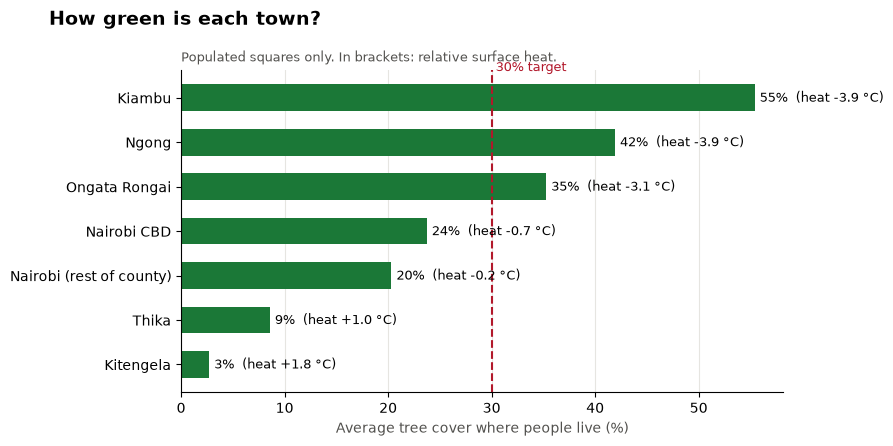

In [38]:
town_sum = pp.groupby("area").apply(lambda d: pd.Series({
    "relative_heat_C": d.lst_rel.mean(),
    "tree_cover_pct": d.tree_pct.mean(),
    "share_people_act_first": d.loc[d.priority_class == "Act first", "people_km2"].sum() / d.people_km2.sum(),
}), include_groups=False).round(3).sort_values("relative_heat_C", ascending=False)
town_sum.to_csv(OUT / "table_towns_green.csv")
display(town_sum)

fig, ax = plt.subplots(figsize=(9, 4.5))
ts = town_sum.sort_values("tree_cover_pct")
ax.barh(ts.index, ts.tree_cover_pct, color="#1b7837", height=0.6)
ax.axvline(CANOPY_TARGET * 100, color="#b2182b", ls="--", lw=1.5)
ax.text(CANOPY_TARGET * 100, len(ts) - 0.4, " 30% target", color="#b2182b", fontsize=9)
for i, (v, h) in enumerate(zip(ts.tree_cover_pct, ts.relative_heat_C)):
    ax.text(v + 0.5, i, f"{v:.0f}%  (heat {h:+.1f} °C)", va="center", fontsize=9)
ax.grid(axis="x", color="#e6e5e1"); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlabel("Average tree cover where people live (%)", color="#52514e")
fig.suptitle("How green is each town?", x=0.06, ha="left", fontsize=14, fontweight="bold")
ax.set_title("Populated squares only. In brackets: relative surface heat.", loc="left", fontsize=9, color="#52514e")
fig.tight_layout(); fig.savefig(OUT / "chart3_towns_tree_cover.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 9 — Take it away: files for QGIS, the web and the brief

### Step 9.1: Save the grid with every result

**What:** one **GeoPackage** (`greening_grid.gpkg`) holding all squares with heat, trees, people, 3-30-300 class and priority.
**Why:** open it in QGIS to make print-quality maps with your own styling, join it to ward boundaries, or load it into your Kenya Climate Intelligence Platform.

In [39]:
keep = ["area", "lat", "lon", "lst_rel", "lst_abs", "ndvi", "tree_pct", "built_pct", "elev",
        "people_km2", "access300_pct", "populated", "geometry"]
out = g[keep].merge(pp[["rule_class", "priority", "priority_class"]], left_index=True, right_index=True, how="left")
out.to_file(OUT / "greening_grid.gpkg", driver="GPKG")
print("Saved:", OUT / "greening_grid.gpkg")

Saved: outputs_02\greening_grid.gpkg


### Step 9.2: Download the 30 m heat and greenness rasters (GeoTIFF)

**What:** save the relative-heat and NDVI images as GeoTIFF files.
**Why:** the 1 km grid is great for decisions, but the 30 m rasters show individual estates, roads and parks. They make striking close-up maps (Mathare vs Karura, for example) in QGIS.

In [40]:
region = metro_geom.bounds()

def download_tif(img, name):
    # Try the direct download up to 3 times; if Earth Engine keeps refusing, send it to Google Drive instead.
    path = OUT / f"{name}.tif"
    for attempt in range(3):
        geemap.ee_export_image(img.toFloat(), filename=str(path), scale=30, region=region, crs=UTM)
        if path.exists() and path.stat().st_size > 0:
            print(f"Saved: {path}")
            return
        time.sleep(10)
    task = ee.batch.Export.image.toDrive(img.toFloat(), description=name, region=region, scale=30, crs=UTM,
                                         maxPixels=1e10)
    task.start()
    print(f"Direct download failed for {name}; started a Google Drive export instead. "
          f"Check the 'Tasks' tab at code.earthengine.google.com, then download {name}.tif from your Google Drive.")

download_tif(lst_rel, "heat_relative_30m")
download_tif(ndvi, "ndvi_30m")


Generating URL ...
Please wait ...
Data downloaded to e:\nairobi-heat-elnino\outputs_02\heat_relative_30m.tif
Generating URL ...
Please wait ...
An error occurred while downloading.


### Step 9.3: The interactive web map

**What:** a zoomable map with satellite imagery, heat, greenness and the priority squares, saved as `interactive_map.html`.
**Why:** it's the most shareable output. Anyone can open it in a browser, zoom into their own estate and see the evidence. Host it on GitHub Pages or link it from your portfolio.

In [41]:
prio_fc = geemap.gdf_to_ee(out[out.priority_class.isin(["Act first", "Act next"])][["priority_class", "geometry"]])
web = geemap.Map(center=[-1.28, 36.85], zoom=11)
web.add_basemap("SATELLITE")
web.addLayer(ndvi, {"min": 0, "max": 0.8, "palette": ["#f7fcf5", "#74c476", "#00441b"]}, "Greenness (NDVI)", False)
web.addLayer(lst_rel, heat_vis, "Relative surface heat (°C)")
web.addLayer(prio_fc.filter(ee.Filter.eq("priority_class", "Act first")).style(color="7a0177", fillColor="7a017766"),
             {}, "Greening priority: act first")
web.addLayer(prio_fc.filter(ee.Filter.eq("priority_class", "Act next")).style(color="dd3497", fillColor="dd349744"),
             {}, "Greening priority: act next", False)
web.add_colorbar(heat_vis, label="°C hotter (red) / cooler (blue) than the area's middle value")
web.to_html(str(OUT / "interactive_map.html"))
print("Saved:", OUT / "interactive_map.html")
web

Saved: outputs_02\interactive_map.html


Map(center=[-1.28, 36.85], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

### Step 9.4: The findings, in plain sentences

In [42]:
L = [
    f"WHERE IT'S HOTTEST: the hottest tenth of Greater Nairobi's populated squares run on average "
    f"{pp.loc[pp.lst_rel >= pp.lst_rel.quantile(0.9), 'lst_rel'].mean():+.1f} °C above the area's middle value in the hot "
    f"season, and the coolest tenth {pp.loc[pp.lst_rel <= pp.lst_rel.quantile(0.1), 'lst_rel'].mean():+.1f} °C. The hottest town "
    f"area is {town_sum.index[0]} ({town_sum.relative_heat_C.iloc[0]:+.1f} °C).",
    f"GREENERY COOLS: at the same altitude and building density, each extra 10% of tree cover goes with "
    f"{b_tree10:+.2f} °C of surface heat ({verdict(p['tree_pct_per10'])}).",
    f"REACH: built-up areas next to a 1 ha+ tree patch are about {far - near:.1f} °C cooler than those over 1 km away; "
    f"the cooling fades by roughly {reach:.0f} m.",
    f"3-30-300: {summary_rule.loc[summary_rule.index != 'Meets both', 'people_share'].sum():.0%} of residents live in "
    f"squares that miss the 30% canopy target, the 300 m access target, or both.",
    f"SOLUTION: bringing the {len(target)} highest-priority squares up to 30% tree cover could cool surfaces by about "
    f"{abs(avg_cool):.1f} °C for roughly {round(people, -3):,.0f} residents. The top priority area is around "
    f"{top.iloc[0]['area']} ({top.iloc[0]['lat']}, {top.iloc[0]['lon']}).",
]
findings = "\n\n".join(L)
print(findings)
(OUT / "findings_02.txt").write_text(findings, encoding="utf-8")

WHERE IT'S HOTTEST: the hottest tenth of Greater Nairobi's populated squares run on average +3.8 °C above the area's middle value in the hot season, and the coolest tenth -7.1 °C. The hottest town area is Kitengela (+1.8 °C).

GREENERY COOLS: at the same altitude and building density, each extra 10% of tree cover goes with -1.02 °C of surface heat (a clear link).

REACH: built-up areas next to a 1 ha+ tree patch are about 4.0 °C cooler than those over 1 km away; the cooling fades by roughly 450 m.

3-30-300: 86% of residents live in squares that miss the 30% canopy target, the 300 m access target, or both.

SOLUTION: bringing the 208 highest-priority squares up to 30% tree cover could cool surfaces by about 2.6 °C for roughly 3,029,000 residents. The top priority area is around Nairobi (rest of county) (-1.26, 36.93).


829

---
## What this notebook can and can't claim

1. **Surface heat, not air heat.** Landsat measures roofs and ground at about 10:30 am. Air temperature differences between estates are smaller, usually a third to half as large, but follow the same pattern.
2. **Association, carefully controlled.** The tree-cooling number accounts for altitude and building density, but other factors (roof materials, water bodies, soil) aren't in the model. Call it *"the cooling associated with trees"*.
3. **WorldCover is from 2021.** Recent construction or clearing won't show. The Sentinel-2 greenness layer (2024–2026) is your up-to-date cross-check.
4. **WorldPop is a 2020 model of population**, not a census count. Good for comparing areas, not for exact numbers.
5. **The scenario is a rough estimate** of scale. It assumes the cooling relationship holds when trees are added, which planting studies elsewhere generally support.
6. **The "3 trees" part of 3-30-300** can't be measured from satellites.

## Everything this produces (`outputs_02/`)

| File | What it is |
|---|---|
| `map1_heat.png` | Where heat builds up |
| `map2_tree_cover.png` | Where the trees are |
| `map3_3-30-300_gaps.png` | Where the green standard is missed |
| `map4_greening_priority.png` | **The solution map**: where to plant first |
| `chart1_trees_vs_heat.png` | More trees, less heat |
| `chart2_cooling_distance.png` | How far green space cooling reaches |
| `chart3_towns_tree_cover.png` | Each town vs the 30% target |
| `table_top20_greening_priority.csv` | Top 20 squares with coordinates and Google Maps links |
| `greening_grid.gpkg` | Every square with every result, for QGIS |
| `heat_relative_30m.tif`, `ndvi_30m.tif` | 30 m rasters for close-up maps |
| `interactive_map.html` | Shareable zoomable web map |
| `findings_02.txt` | Plain-sentence findings |